# Supermarket Sales Analysis
**Data Analytics Project (IBM Internship)**

Goal: study 500 supermarket sales transactions and find useful information about products, branches, categories, customers, payments and ratings.

## 1. Import libraries and load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('supermarket_sales.csv')
df['Date'] = pd.to_datetime(df['Date'])
print(df.shape)
df.head()

(500, 13)


,Invoice ID,Date,Branch,City,Customer Type,Gender,Product,Category,Quantity,Unit Price,Payment,Rating,Sales
0,INV0001,2026-06-01,A,Jaipur,Member,Male,Milk,Dairy,4,57.13,UPI,3.8,228.52
1,INV0002,2026-02-26,A,Jaipur,Normal,Male,Rice,Grocery,9,66.85,Net Banking,3.9,601.65
2,INV0003,2026-02-09,C,Mumbai,Normal,Female,Milk,Dairy,3,57.28,Card,3.4,171.84
3,INV0004,2026-01-12,C,Mumbai,Member,Female,Shampoo,Personal Care,2,168.27,Card,4.5,336.54
4,INV0005,2026-06-30,A,Jaipur,Normal,Female,Apples,Fruits,5,130.57,Cash,3.1,652.85


## 2. Check the data

In [2]:
df.info()
print('Missing values:', df.isnull().sum().sum())
print('Duplicate invoices:', df['Invoice ID'].duplicated().sum())
print('Quantity range:', df['Quantity'].min(), 'to', df['Quantity'].max())
print('Rating range:', df['Rating'].min(), 'to', df['Rating'].max())
print('Unit price min:', df['Unit Price'].min())

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Invoice ID     500 non-null    str           
 1   Date           500 non-null    datetime64[us]
 2   Branch         500 non-null    str           
 3   City           500 non-null    str           
 4   Customer Type  500 non-null    str           
 5   Gender         500 non-null    str           
 6   Product        500 non-null    str           
 7   Category       500 non-null    str           
 8   Quantity       500 non-null    int64         
 9   Unit Price     500 non-null    float64       
 10  Payment        500 non-null    str           
 11  Rating         500 non-null    float64       
 12  Sales          500 non-null    float64       
dtypes: datetime64[us](1), float64(3), int64(1), str(8)
memory usage: 50.9 KB
Missing values: 0
Duplicate invoices: 0
Quantity range: 1 to 10

The data has 500 rows, no missing values and no duplicate invoices. Quantity, price and rating values are all in a sensible range.

## 3. Verify Sales = Quantity x Unit Price

In [3]:
calc = (df['Quantity'] * df['Unit Price']).round(2)
wrong = (calc - df['Sales']).abs() > 0.01
print('Rows where Sales does not match:', wrong.sum())
print('Total sales: Rs', round(df['Sales'].sum(), 2))
print('Date range:', df['Date'].min().date(), 'to', df['Date'].max().date())

Rows where Sales does not match: 0
Total sales: Rs 244411.08
Date range: 2026-01-01 to 2026-07-01


The Sales column matches Quantity x Unit Price in every row, so I use it directly.

## 4. Analysis
### Q1. Which product generates the highest sales?

Product
Cheese         27906.30
Coffee         27694.87
Shampoo        27497.48
Cooking Oil    21525.06
Tea            17681.59
Name: Sales, dtype: float64


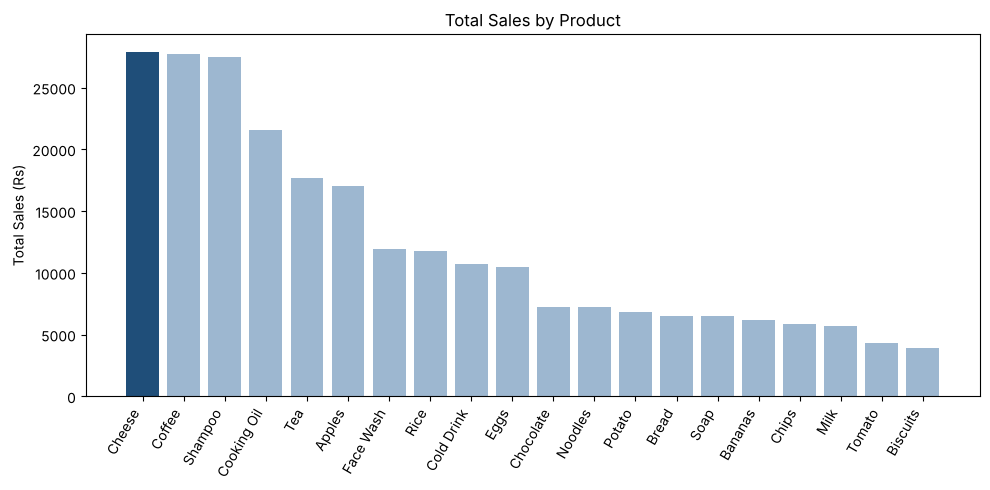

In [4]:
product_sales = df.groupby('Product')['Sales'].sum().sort_values(ascending=False)
print(product_sales.head(5).round(2))

plt.figure(figsize=(10,5))
colors = ['#1f4e79' if i == 0 else '#9db7d0' for i in range(len(product_sales))]
plt.bar(product_sales.index, product_sales.values, color=colors)
plt.xticks(rotation=60, ha='right')
plt.ylabel('Total Sales (Rs)')
plt.title('Total Sales by Product')
plt.tight_layout()
plt.savefig('chart1_product.png', dpi=150)
plt.show()

**Cheese** is the top product with Rs 27,906.30, but Coffee (Rs 27,694.87) and Shampoo (Rs 27,497.48) are very close, so the top three are almost tied.

### Q2. Which branch performs best?

  Branch       City     Sales          Label
0      C     Mumbai  72469.45     C (Mumbai)
1      B      Delhi  64116.26      B (Delhi)
2      D  Bengaluru  55468.29  D (Bengaluru)
3      A     Jaipur  52357.08     A (Jaipur)


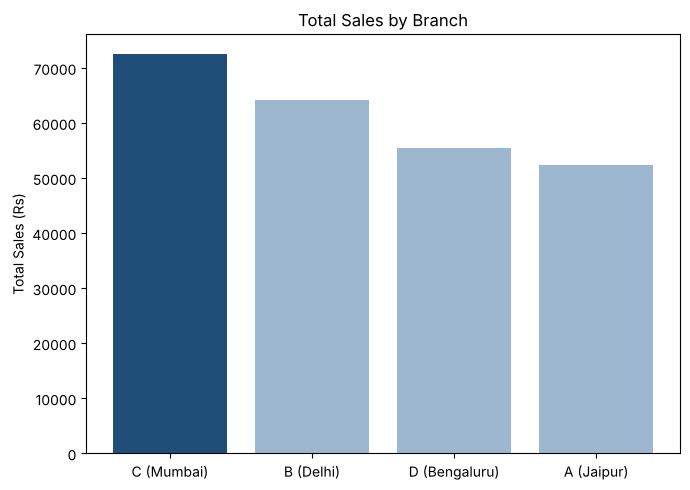

In [5]:
branch_sales = df.groupby(['Branch','City'])['Sales'].sum().sort_values(ascending=False).reset_index()
branch_sales['Label'] = branch_sales['Branch'] + ' (' + branch_sales['City'] + ')'
print(branch_sales.round(2))

plt.figure(figsize=(7,5))
colors = ['#1f4e79'] + ['#9db7d0'] * 3
plt.bar(branch_sales['Label'], branch_sales['Sales'], color=colors)
plt.ylabel('Total Sales (Rs)')
plt.title('Total Sales by Branch')
plt.tight_layout()
plt.savefig('chart2_branch.png', dpi=150)
plt.show()

**Branch C (Mumbai)** is the best with Rs 72,469.45. Branch A (Jaipur) is the lowest with Rs 52,357.08.

### Q3. Which category sells the most?

Category
Beverages        56108.24
Personal Care    45943.96
Dairy            43992.00
Grocery          40470.47
Fruits           23263.17
Snacks           16992.97
Vegetables       11124.17
Bakery            6516.10
Name: Sales, dtype: float64


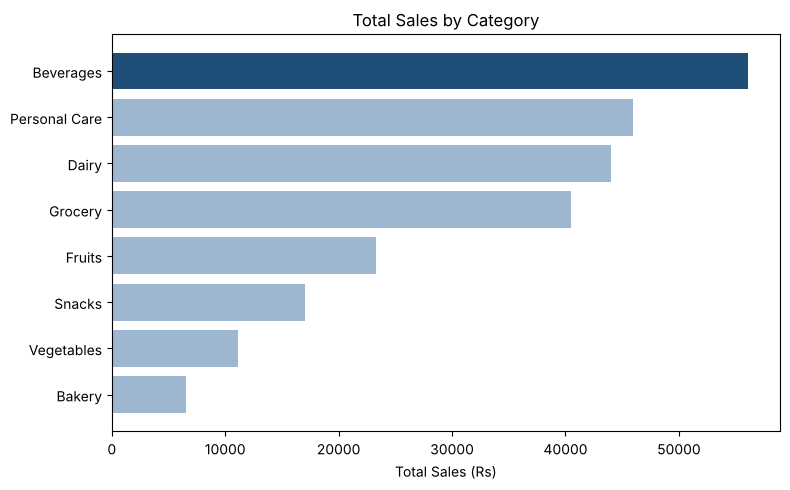

In [6]:
cat_sales = df.groupby('Category')['Sales'].sum().sort_values()
print(cat_sales.sort_values(ascending=False).round(2))

plt.figure(figsize=(8,5))
colors = ['#9db7d0'] * (len(cat_sales)-1) + ['#1f4e79']
plt.barh(cat_sales.index, cat_sales.values, color=colors)
plt.xlabel('Total Sales (Rs)')
plt.title('Total Sales by Category')
plt.tight_layout()
plt.savefig('chart3_category.png', dpi=150)
plt.show()

**Beverages** lead with Rs 56,108.24, followed by Personal Care and Dairy. Bakery is the weakest category.

### Q4. What is the most popular payment method?

Payment
UPI            127
Net Banking    126
Card           125
Cash           122
Name: count, dtype: int64


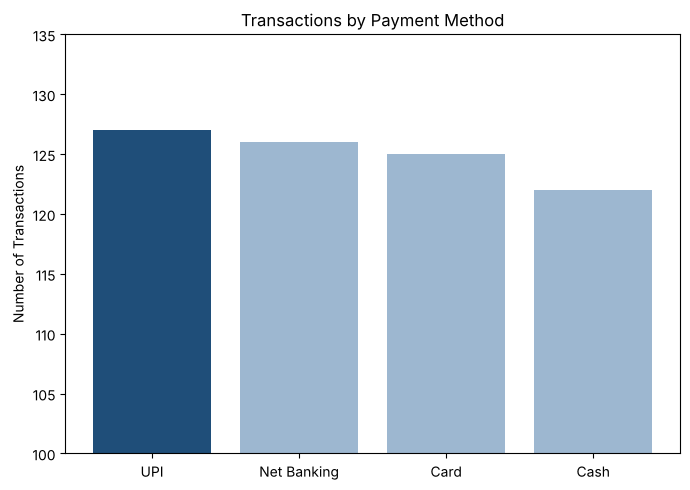

In [7]:
pay = df['Payment'].value_counts()
print(pay)

plt.figure(figsize=(7,5))
colors = ['#1f4e79'] + ['#9db7d0'] * 3
plt.bar(pay.index, pay.values, color=colors)
plt.ylabel('Number of Transactions')
plt.title('Transactions by Payment Method')
plt.ylim(100, 135)
plt.tight_layout()
plt.savefig('chart4_payment.png', dpi=150)
plt.show()

**UPI** is used most (127 transactions), but the four methods are very close (122 to 127), so customers use all of them almost equally. The y-axis starts at 100 to make the small gap visible.

### Q5. Do Members spend more than Normal customers?

                 mean  count
Customer Type               
Member         483.14    296
Normal         497.07    204


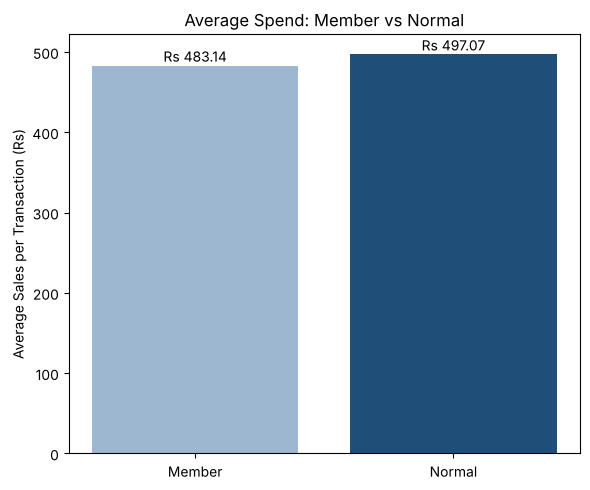

In [8]:
cust = df.groupby('Customer Type')['Sales'].agg(['mean','count'])
print(cust.round(2))

plt.figure(figsize=(6,5))
plt.bar(cust.index, cust['mean'], color=['#9db7d0','#1f4e79'])
for i, v in enumerate(cust['mean']):
    plt.text(i, v + 5, f'Rs {v:.2f}', ha='center')
plt.ylabel('Average Sales per Transaction (Rs)')
plt.title('Average Spend: Member vs Normal')
plt.tight_layout()
plt.savefig('chart5_customer.png', dpi=150)
plt.show()

**No.** Members average Rs 483.14 and Normal customers average Rs 497.07 per transaction. The difference is small (about Rs 14), so membership is not clearly increasing spending.

### Q6. What is the average customer rating?

Average rating: 3.99
City
Bengaluru    4.09
Delhi        3.98
Jaipur       3.84
Mumbai       4.05
Name: Rating, dtype: float64


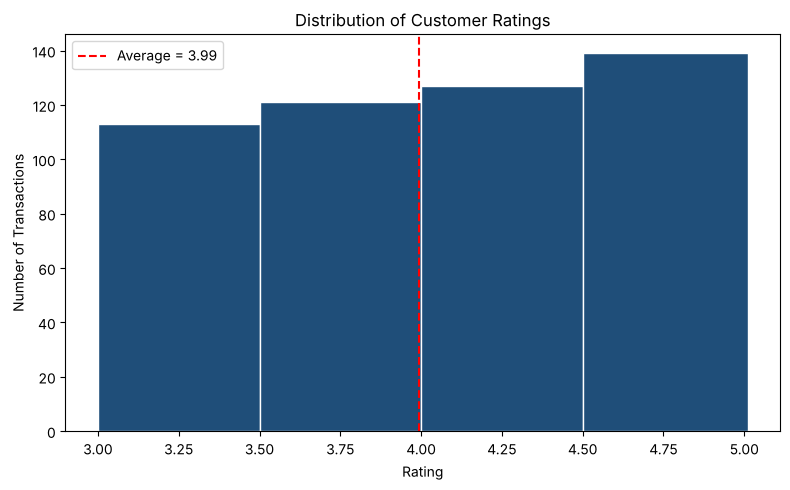

In [9]:
print('Average rating:', round(df['Rating'].mean(), 2))
print(df.groupby('City')['Rating'].mean().round(2))

plt.figure(figsize=(8,5))
plt.hist(df['Rating'], bins=[3,3.5,4,4.5,5.01], color='#1f4e79', edgecolor='white')
plt.axvline(df['Rating'].mean(), color='red', linestyle='--', label='Average = 3.99')
plt.xlabel('Rating')
plt.ylabel('Number of Transactions')
plt.title('Distribution of Customer Ratings')
plt.legend()
plt.tight_layout()
plt.savefig('chart6_rating.png', dpi=150)
plt.show()

The average rating is **3.99 out of 5**. Ratings range from 3.0 to 5.0, and nobody gave less than 3.

## 5. Extra analysis: monthly sales trend

Date
2026-01    43415.53
2026-02    30068.15
2026-03    37306.42
2026-04    52569.77
2026-05    42542.31
2026-06    35041.46
2026-07     3467.44
Freq: M, Name: Sales, dtype: float64


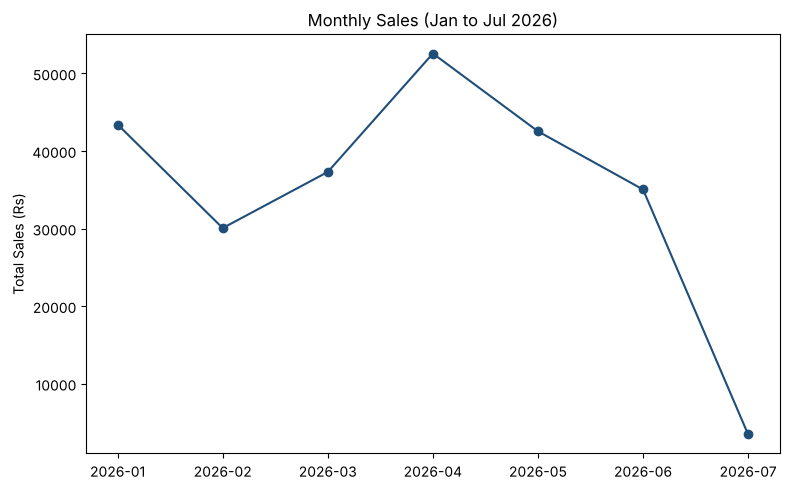

In [10]:
monthly = df.groupby(df['Date'].dt.to_period('M'))['Sales'].sum()
print(monthly.round(2))

plt.figure(figsize=(8,5))
plt.plot(monthly.index.astype(str), monthly.values, marker='o', color='#1f4e79')
plt.ylabel('Total Sales (Rs)')
plt.title('Monthly Sales (Jan to Jul 2026)')
plt.tight_layout()
plt.savefig('chart7_monthly.png', dpi=150)
plt.show()

July has only a few days of data in this file, so its low value should not be read as a drop in sales.

## 6. Business decisions
- Keep more stock of Cheese, Coffee and Shampoo, and of the Beverages, Personal Care and Dairy categories.
- Study why Branch C (Mumbai) does well and apply the same practices at Branch A (Jaipur).
- Support all payment methods; UPI is slightly ahead but the others are almost as popular.
- Members do not spend more than Normal customers, so membership offers should be redesigned to encourage bigger purchases.
- Improve customer service to lift the average rating above 3.99.

## 7. Conclusion
The analysis turns raw transaction data into simple findings that help the supermarket understand its performance. All numbers were calculated from the dataset of 500 transactions.